In [1]:
import torch
print(torch.cuda.is_available())

True


In [21]:
from pathlib import Path

current_dir = Path.cwd()
candidates = [current_dir, *current_dir.parents, current_dir / "RoadVision-AI"]
PROJECT_ROOT = next(
    (path for path in candidates if (path / "Dataset" / "train").is_dir()),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not find RoadVision-AI/Dataset/train from the notebook working directory.")

RDD_ROOT = PROJECT_ROOT / "Dataset" / "train"
YOLO_ROOT = PROJECT_ROOT / "prepared_dataset" / "road_damage"
RUN_DIR = PROJECT_ROOT / "runs" / "road_damage_yolo26n"
BEST_WEIGHTS = RUN_DIR / "weights" / "best.pt"
CHECKPOINT_PATH = PROJECT_ROOT / "model" / "road_damage_yolo26n_best.pt"

print("Project root:", PROJECT_ROOT)
print("Source dataset:", RDD_ROOT)
print("Prepared YOLO dataset:", YOLO_ROOT)
print("Training output:", RUN_DIR)

Project root: d:\HONORS\RoadVision-AI
Source dataset: d:\HONORS\RoadVision-AI\Dataset\train
Prepared YOLO dataset: d:\HONORS\RoadVision-AI\prepared_dataset\road_damage
Training output: d:\HONORS\RoadVision-AI\runs\road_damage_yolo26n


In [3]:
# Count images and XML annotations
for country in ["India", "Japan", "Czech"]:
    image_dir = RDD_ROOT / country / "images"
    annotation_dir = RDD_ROOT / country / "annotations" / "xmls"

    images = list(image_dir.glob("*.jpg"))
    xmls = list(annotation_dir.glob("*.xml"))

    print(f"\n{country}")
    print(f"  Images: {len(images)}")
    print(f"  XML annotations: {len(xmls)}")


India
  Images: 7706
  XML annotations: 7706

Japan
  Images: 10506
  XML annotations: 10506

Czech
  Images: 2829
  XML annotations: 2829


In [4]:
# Inspect one local annotation
import xml.etree.ElementTree as ET

xml_file = next(RDD_ROOT.rglob("*.xml"))
print("XML file:", xml_file)

root = ET.parse(xml_file).getroot()
print("\nImage filename:", root.findtext("filename"))

size = root.find("size")
print("Image size:")
print("Width :", size.findtext("width"))
print("Height:", size.findtext("height"))

print("\nDamage objects:")
for obj in root.findall("object"):
    bbox = obj.find("bndbox")
    print(
        f"Class: {obj.findtext('name')} | Bounding box: "
        f"({bbox.findtext('xmin')}, {bbox.findtext('ymin')}, "
        f"{bbox.findtext('xmax')}, {bbox.findtext('ymax')})"
    )

XML file: d:\HONORS\RoadVision-AI\Dataset\train\Czech\annotations\xmls\Czech_000000.xml

Image filename: Czech_000000.jpg
Image size:
Width : 600
Height: 600

Damage objects:


In [5]:
# Create generated YOLO dataset folders
for split in ["train", "val", "test"]:
    (YOLO_ROOT / "images" / split).mkdir(parents=True, exist_ok=True)
    (YOLO_ROOT / "labels" / split).mkdir(parents=True, exist_ok=True)

print("Generated dataset folder:", YOLO_ROOT)

Generated dataset folder: d:\HONORS\RoadVision-AI\prepared_dataset\road_damage


In [6]:
#create and test the converter
import xml.etree.ElementTree as ET
from pathlib import Path

# RDD2020 classes
CLASS_MAP = {
    "D00": 0,  # Longitudinal crack
    "D10": 1,  # Transverse crack
    "D20": 2,  # Alligator crack
    "D40": 3   # Pothole
}

def xml_to_yolo(xml_path):
    """
    Convert one RDD2020 Pascal VOC XML file
    into YOLO annotation lines.
    """

    tree = ET.parse(xml_path)
    root = tree.getroot()

    # Image dimensions
    size = root.find("size")
    image_width = int(size.find("width").text)
    image_height = int(size.find("height").text)

    yolo_lines = []

    # Process every damage object
    for obj in root.findall("object"):

        class_name = obj.find("name").text.strip()

        # Ignore classes that aren't part of our 4 target classes
        if class_name not in CLASS_MAP:
            continue

        bbox = obj.find("bndbox")

        xmin = float(bbox.find("xmin").text)
        ymin = float(bbox.find("ymin").text)
        xmax = float(bbox.find("xmax").text)
        ymax = float(bbox.find("ymax").text)

        # Convert bounding box to YOLO format
        center_x = ((xmin + xmax) / 2) / image_width
        center_y = ((ymin + ymax) / 2) / image_height

        width = (xmax - xmin) / image_width
        height = (ymax - ymin) / image_height

        class_id = CLASS_MAP[class_name]

        yolo_lines.append(
            f"{class_id} "
            f"{center_x:.6f} "
            f"{center_y:.6f} "
            f"{width:.6f} "
            f"{height:.6f}"
        )

    return yolo_lines

In [7]:
test_xml = RDD_ROOT / "India" / "annotations" / "xmls" / "India_009612.xml"
annotations = xml_to_yolo(test_xml)

print("YOLO annotations:")
for line in annotations:
    print(line)

YOLO annotations:
2 0.554861 0.847222 0.398611 0.305556
3 0.465972 0.856250 0.040278 0.045833
3 0.502778 0.642361 0.052778 0.040278
3 0.493750 0.768056 0.045833 0.086111


In [8]:
import random
import shutil

TRAIN_RATIO = 0.70
VAL_RATIO = 0.15
TEST_RATIO = 0.15
RANDOM_SEED = 42

random.seed(RANDOM_SEED)
all_pairs = []

for country_dir in RDD_ROOT.iterdir():
    if not country_dir.is_dir():
        continue

    image_dir = country_dir / "images"
    xml_dir = country_dir / "annotations" / "xmls"

    for image_path in image_dir.glob("*.jpg"):
        xml_path = xml_dir / f"{image_path.stem}.xml"
        if xml_path.exists():
            all_pairs.append((image_path, xml_path))

if not all_pairs:
    raise FileNotFoundError(f"No matching JPG/XML pairs found under {RDD_ROOT}")

random.shuffle(all_pairs)
total = len(all_pairs)
train_end = int(total * TRAIN_RATIO)
val_end = train_end + int(total * VAL_RATIO)

splits = {
    "train": all_pairs[:train_end],
    "val": all_pairs[train_end:val_end],
    "test": all_pairs[val_end:],
}

print("Total image/XML pairs:", total)
for split, pairs in splits.items():
    print(f"{split.title()}: {len(pairs)}")

if YOLO_ROOT.exists():
    shutil.rmtree(YOLO_ROOT)

for split, pairs in splits.items():
    image_output = YOLO_ROOT / "images" / split
    label_output = YOLO_ROOT / "labels" / split
    image_output.mkdir(parents=True, exist_ok=True)
    label_output.mkdir(parents=True, exist_ok=True)

    for index, (image_path, xml_path) in enumerate(pairs, start=1):
        shutil.copy2(image_path, image_output / image_path.name)
        yolo_lines = xml_to_yolo(xml_path)
        label_path = label_output / f"{image_path.stem}.txt"
        label_path.write_text("\n".join(yolo_lines), encoding="utf-8")

        if index % 1000 == 0:
            print(f"{split}: processed {index}/{len(pairs)}")

print("\nConversion complete")
print("Output:", YOLO_ROOT)

Total image/XML pairs: 21041
Train: 14728
Val: 3156
Test: 3157
train: processed 1000/14728
train: processed 2000/14728
train: processed 3000/14728
train: processed 4000/14728
train: processed 5000/14728
train: processed 6000/14728
train: processed 7000/14728
train: processed 8000/14728
train: processed 9000/14728
train: processed 10000/14728
train: processed 11000/14728
train: processed 12000/14728
train: processed 13000/14728
train: processed 14000/14728
val: processed 1000/3156
val: processed 2000/3156
val: processed 3000/3156
test: processed 1000/3157
test: processed 2000/3157
test: processed 3000/3157

Conversion complete
Output: d:\HONORS\RoadVision-AI\prepared_dataset\road_damage


In [9]:
# Verify image/label matching
for split in ["train", "val", "test"]:
    image_dir = YOLO_ROOT / "images" / split
    label_dir = YOLO_ROOT / "labels" / split

    images = {path.stem for path in image_dir.glob("*.jpg")}
    labels = {path.stem for path in label_dir.glob("*.txt")}

    print(f"\n{split.upper()}")
    print("Images:", len(images))
    print("Labels:", len(labels))
    print("Images without labels:", len(images - labels))
    print("Labels without images:", len(labels - images))


TRAIN
Images: 14728
Labels: 14728
Images without labels: 0
Labels without images: 0

VAL
Images: 3156
Labels: 3156
Images without labels: 0
Labels without images: 0

TEST
Images: 3157
Labels: 3157
Images without labels: 0
Labels without images: 0


In [10]:
# Create the Ultralytics dataset configuration
names = [
    "Longitudinal Crack",
    "Transverse Crack",
    "Alligator Crack",
    "Pothole",
]

data_yaml = f'''path: "{YOLO_ROOT.as_posix()}"
train: images/train
val: images/val
test: images/test

names:
  0: Longitudinal Crack
  1: Transverse Crack
  2: Alligator Crack
  3: Pothole
'''

yaml_path = YOLO_ROOT / "data.yaml"
yaml_path.write_text(data_yaml, encoding="utf-8")

print("data.yaml created at:", yaml_path)
print("\nContents:\n")
print(yaml_path.read_text(encoding="utf-8"))

data.yaml created at: d:\HONORS\RoadVision-AI\prepared_dataset\road_damage\data.yaml

Contents:

path: "d:/HONORS/RoadVision-AI/prepared_dataset/road_damage"
train: images/train
val: images/val
test: images/test

names:
  0: Longitudinal Crack
  1: Transverse Crack
  2: Alligator Crack
  3: Pothole



Image: India_001227.jpg
Image size: (720, 720)
Annotations: 0


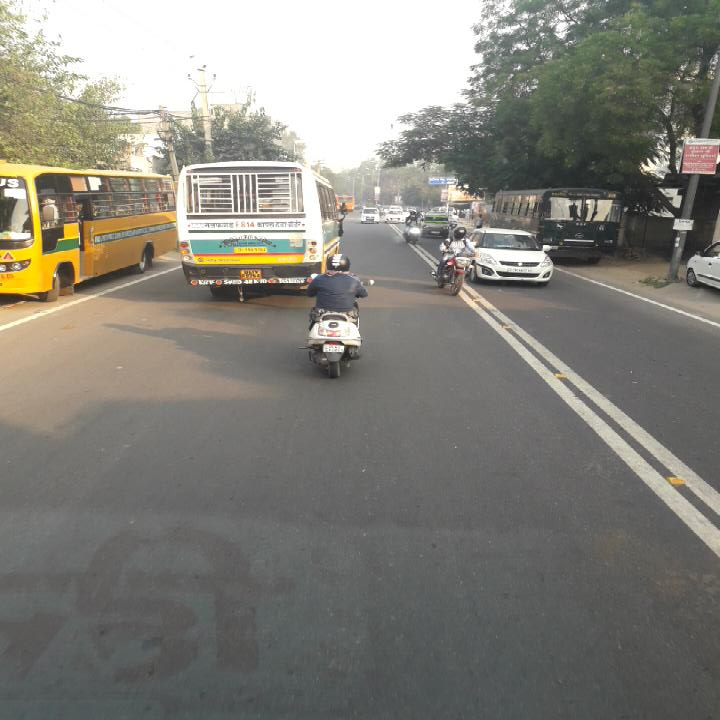

In [11]:
# Visualize YOLO bounding boxes
import random
from PIL import Image, ImageDraw

CLASS_NAMES = {
    0: "Longitudinal Crack",
    1: "Transverse Crack",
    2: "Alligator Crack",
    3: "Pothole",
}

image_path = random.choice(list((YOLO_ROOT / "images" / "val").glob("*.jpg")))
label_path = YOLO_ROOT / "labels" / "val" / f"{image_path.stem}.txt"

image = Image.open(image_path).convert("RGB")
draw = ImageDraw.Draw(image)
width, height = image.size

for line in label_path.read_text(encoding="utf-8").splitlines():
    parts = line.split()
    if len(parts) != 5:
        continue

    class_id = int(parts[0])
    center_x, center_y, box_width, box_height = map(float, parts[1:])
    xmin = int((center_x - box_width / 2) * width)
    ymin = int((center_y - box_height / 2) * height)
    xmax = int((center_x + box_width / 2) * width)
    ymax = int((center_y + box_height / 2) * height)

    draw.rectangle([xmin, ymin, xmax, ymax], outline="red", width=3)
    draw.text((xmin, max(0, ymin - 15)), CLASS_NAMES.get(class_id, "Unknown"), fill="red")

print("Image:", image_path.name)
print("Image size:", image.size)
print("Annotations:", len(label_path.read_text(encoding="utf-8").splitlines()))
display(image)

In [12]:
#load yolo and verify the gpu
import torch
from ultralytics import YOLO

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

CUDA available: True
GPU: NVIDIA GeForce RTX 5080


In [16]:
from ultralytics import YOLO

model = YOLO("yolo26n.pt")
print("YOLO26n pretrained model loaded.")

YOLO26n pretrained model loaded.


In [17]:
from ultralytics import YOLO

model = YOLO("yolo26n.pt")

results = model.train(
    data=str(YOLO_ROOT / "data.yaml"),
    epochs=50,
    imgsz=640,
    batch=8,
    device=0,
    workers=0,
    project=str(PROJECT_ROOT / "runs"),
    name="road_damage_yolo26n",
    patience=10,
    pretrained=True,
    plots=True,
)

print("Best weights:", BEST_WEIGHTS)

New https://pypi.org/project/ultralytics/8.4.182 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.177  Python-3.11.9 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5080, 16303MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=d:\HONORS\RoadVision-AI\prepared_dataset\road_damage\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixu

In [22]:
print("Training run directory:", RUN_DIR)
print("Best checkpoint:", BEST_WEIGHTS)
print("Checkpoint created:", BEST_WEIGHTS.exists())

Training run directory: d:\HONORS\RoadVision-AI\runs\road_damage_yolo26n
Best checkpoint: d:\HONORS\RoadVision-AI\runs\road_damage_yolo26n\weights\best.pt
Checkpoint created: True


In [23]:
print("Best checkpoint exists:", BEST_WEIGHTS.exists())
if BEST_WEIGHTS.exists():
    print("Size:", round(BEST_WEIGHTS.stat().st_size / (1024 * 1024), 2), "MB")

Best checkpoint exists: True
Size: 5.21 MB


In [24]:
from ultralytics import YOLO

best_model = YOLO(str(BEST_WEIGHTS))
test_results = best_model.val(
    data=str(YOLO_ROOT / "data.yaml"),
    split="test",
    imgsz=640,
    batch=8,
    device=0,
    plots=True,
)

print("Test evaluation complete.")

Ultralytics 8.4.177  Python-3.11.9 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5080, 16303MiB)
YOLO26n summary (fused): 121 layers, 2,390,464 parameters, 0 gradients, 5.4 GFLOPs
WARNING val: Slow image access detected (ping: 0.3±0.2 ms, read: 48.5±17.6 MB/s, size: 54.5 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning D:\HONORS\RoadVision-AI\prepared_dataset\road_damage\labels\test... 3157 images, 1361 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 3157/3157 2.9Kit/s 1.1s0.1s
val: New cache created: D:\HONORS\RoadVision-AI\prepared_dataset\road_damage\labels\test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 395/395 14.9it/s 26.5s0.0s
                   all       3157       3669      0.563      0.475      0.493      0.223
    Longitudinal Crack        654        946      0.519      0.385      0.408      0.173
      Tra

Image: Japan_008771.jpg
Detections: 4
  Transverse Crack: 0.38
  Transverse Crack: 0.37
  Transverse Crack: 0.25
  Transverse Crack: 0.25


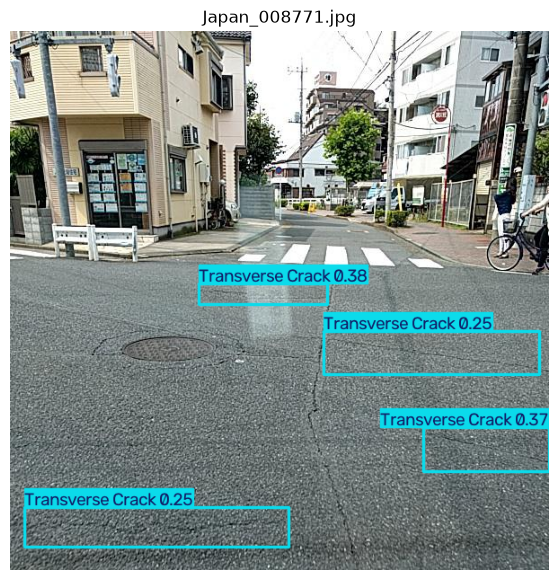

Image: India_000385.jpg
Detections: 0


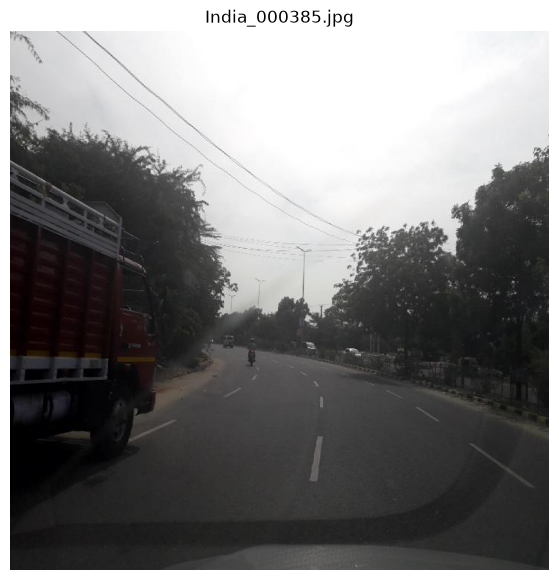

Image: Czech_001083.jpg
Detections: 0


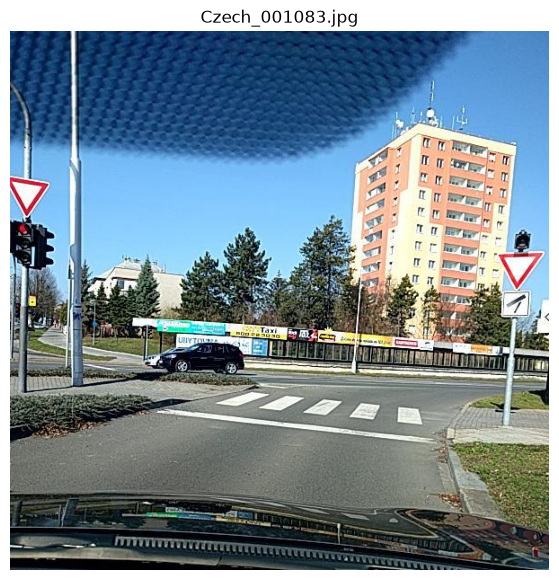

Image: Japan_012071.jpg
Detections: 2
  Transverse Crack: 0.51
  Longitudinal Crack: 0.45


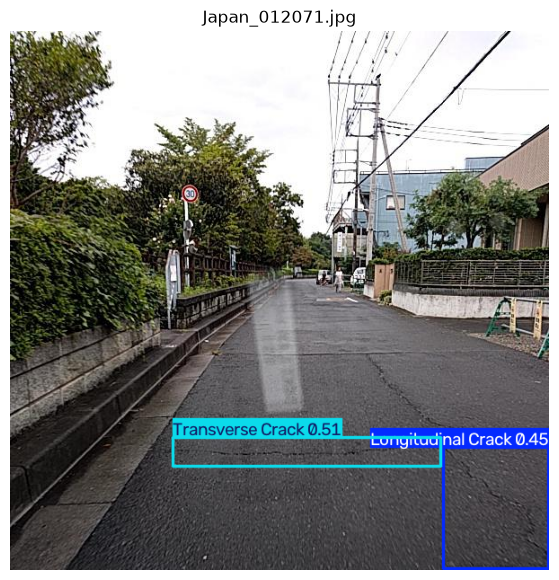

Image: India_006336.jpg
Detections: 0


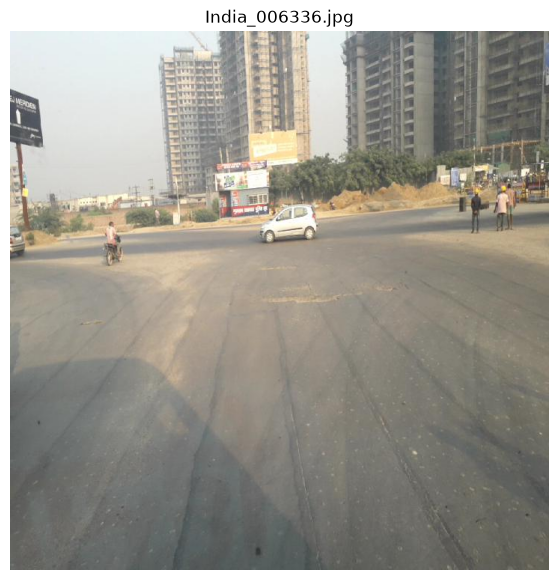

In [25]:
from pathlib import Path
import random
import matplotlib.pyplot as plt
from ultralytics import YOLO

model = YOLO(str(BEST_WEIGHTS))
test_dir = YOLO_ROOT / "images" / "test"
test_images = list(test_dir.glob("*.jpg"))

random.seed(42)
sample_images = random.sample(test_images, min(5, len(test_images)))

for image_path in sample_images:
    predictions = model.predict(
        source=str(image_path),
        imgsz=640,
        conf=0.20,
        device=0,
        verbose=False,
    )
    result = predictions[0]
    print("=" * 60)
    print("Image:", image_path.name)
    print("Detections:", len(result.boxes))

    for box in result.boxes:
        class_id = int(box.cls[0])
        confidence = float(box.conf[0])
        print(f"  {model.names[class_id]}: {confidence:.2f}")

    annotated = result.plot()[:, :, ::-1]
    plt.figure(figsize=(10, 7))
    plt.imshow(annotated)
    plt.title(image_path.name)
    plt.axis("off")
    plt.show()

In [26]:
import shutil

CHECKPOINT_PATH.parent.mkdir(parents=True, exist_ok=True)
shutil.copy2(BEST_WEIGHTS, CHECKPOINT_PATH)

print("Checkpoint saved to:", CHECKPOINT_PATH)
print("Size:", round(CHECKPOINT_PATH.stat().st_size / (1024 ** 2), 2), "MB")

Checkpoint saved to: d:\HONORS\RoadVision-AI\model\road_damage_yolo26n_best.pt
Size: 5.21 MB


In [27]:
test_images = YOLO_ROOT / "images" / "test"
test_labels = YOLO_ROOT / "labels" / "test"

damaged_images = []
for label_file in test_labels.glob("*.txt"):
    if label_file.stat().st_size > 0:
        image_file = test_images / f"{label_file.stem}.jpg"
        if image_file.exists():
            damaged_images.append(image_file)

print("Test images with ground-truth damage:", len(damaged_images))
random.seed(42)
sample_images = random.sample(damaged_images, min(10, len(damaged_images)))

for image_path in sample_images:
    print(image_path.name)

Test images with ground-truth damage: 1796
Japan_007696.jpg
India_001475.jpg
Czech_001344.jpg
Japan_009939.jpg
India_009193.jpg
India_007965.jpg
India_006832.jpg
India_002717.jpg
Japan_009823.jpg
India_001111.jpg


In [28]:
from ultralytics import YOLO

model = YOLO(str(BEST_WEIGHTS))
model.predict(
    source=[str(image_path) for image_path in sample_images],
    conf=0.25,
    save=True,
    project=str(PROJECT_ROOT / "predictions"),
    name="damaged_test_samples",
    exist_ok=True,
)

print("Predictions saved under:", PROJECT_ROOT / "predictions" / "damaged_test_samples")


0: 640x640 (no detections), 0.8ms
1: 640x640 (no detections), 0.8ms
2: 640x640 (no detections), 0.8ms
3: 640x640 2 Transverse Cracks, 0.8ms
4: 640x640 1 Alligator Crack, 0.8ms
5: 640x640 1 Longitudinal Crack, 0.8ms
6: 640x640 1 Alligator Crack, 0.8ms
7: 640x640 1 Longitudinal Crack, 1 Alligator Crack, 0.8ms
8: 640x640 1 Alligator Crack, 0.8ms
9: 640x640 1 Alligator Crack, 0.8ms
Speed: 3.7ms preprocess, 0.8ms inference, 0.8ms postprocess per image at shape (1, 3, 640, 640)
Results saved to D:\HONORS\RoadVision-AI\predictions\damaged_test_samples
Predictions saved under: d:\HONORS\RoadVision-AI\predictions\damaged_test_samples



0: 640x640 (no detections), 1.0ms
1: 640x640 (no detections), 1.0ms
2: 640x640 (no detections), 1.0ms
3: 640x640 2 Transverse Cracks, 1.0ms
4: 640x640 1 Alligator Crack, 1.0ms
5: 640x640 1 Longitudinal Crack, 1.0ms
6: 640x640 1 Alligator Crack, 1.0ms
7: 640x640 1 Longitudinal Crack, 1 Alligator Crack, 1.0ms
8: 640x640 1 Alligator Crack, 1.0ms
9: 640x640 1 Alligator Crack, 1.0ms
Speed: 1.7ms preprocess, 1.0ms inference, 0.6ms postprocess per image at shape (1, 3, 640, 640)


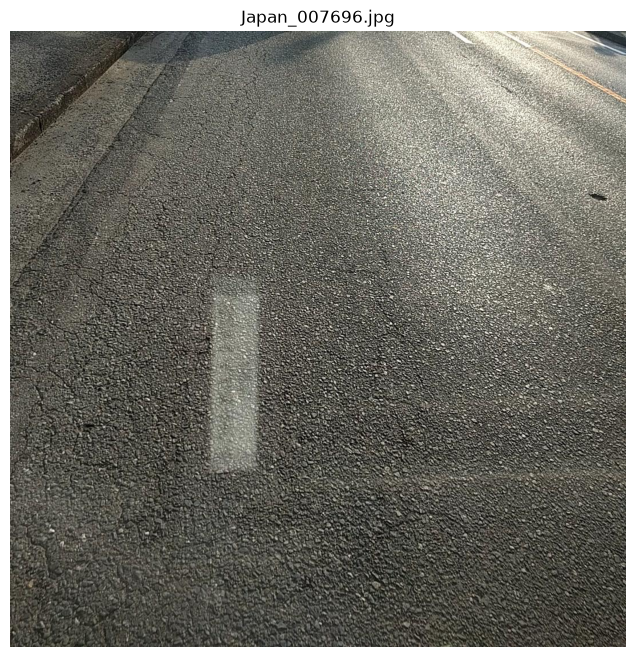

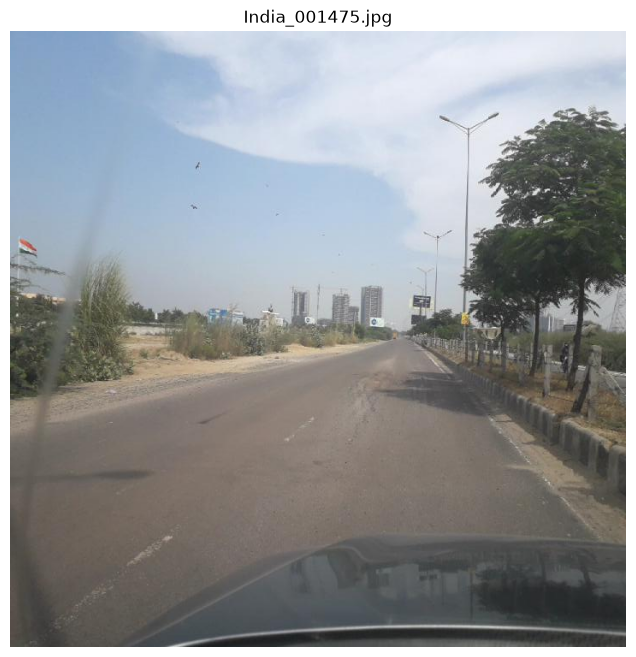

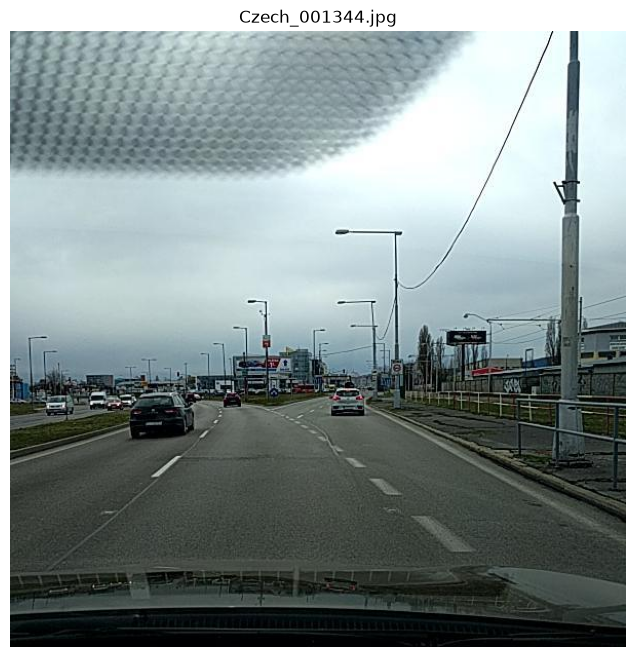

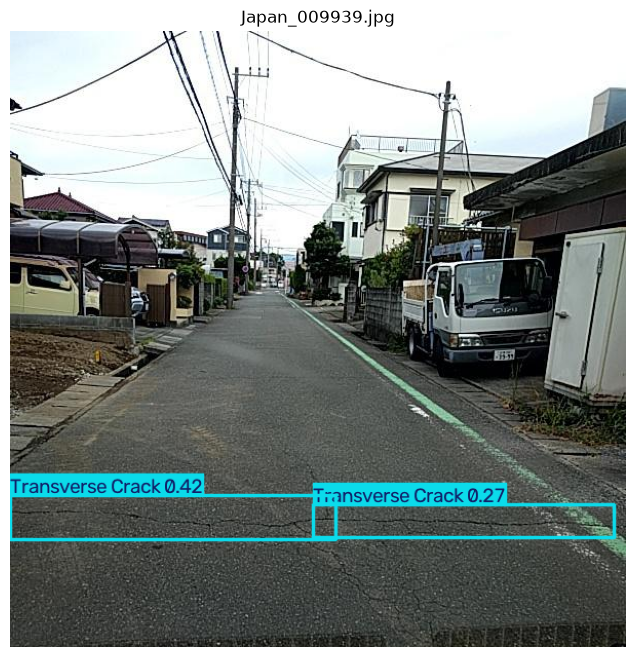

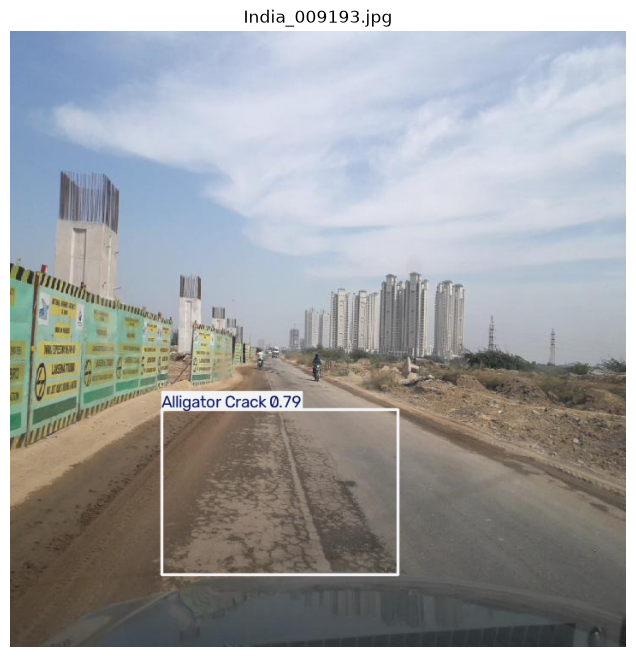

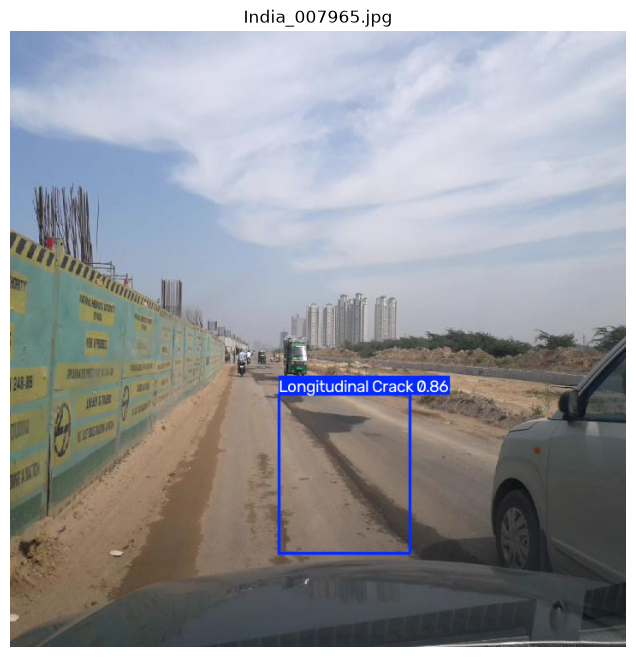

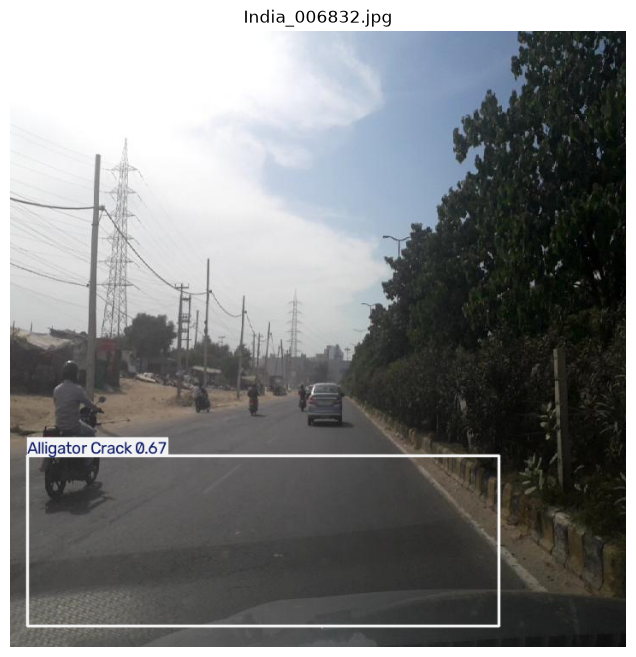

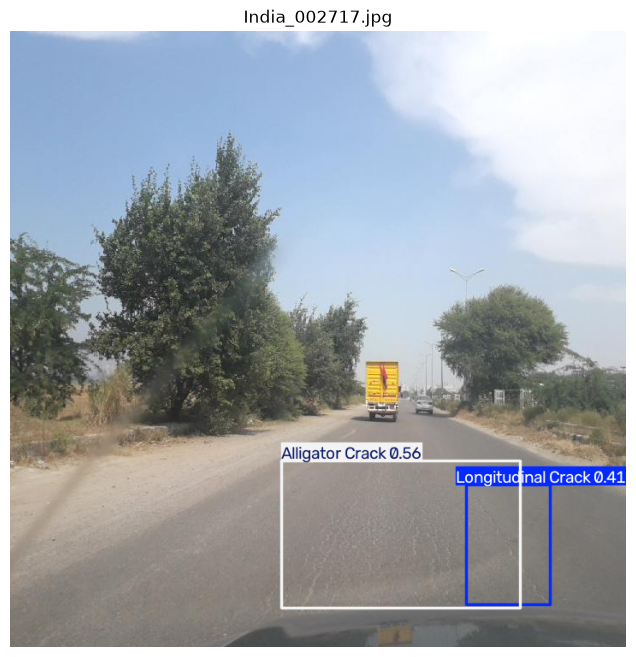

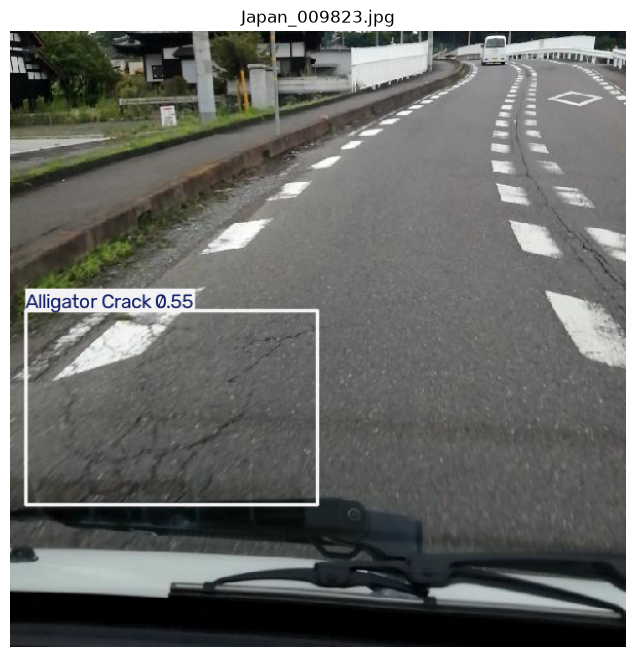

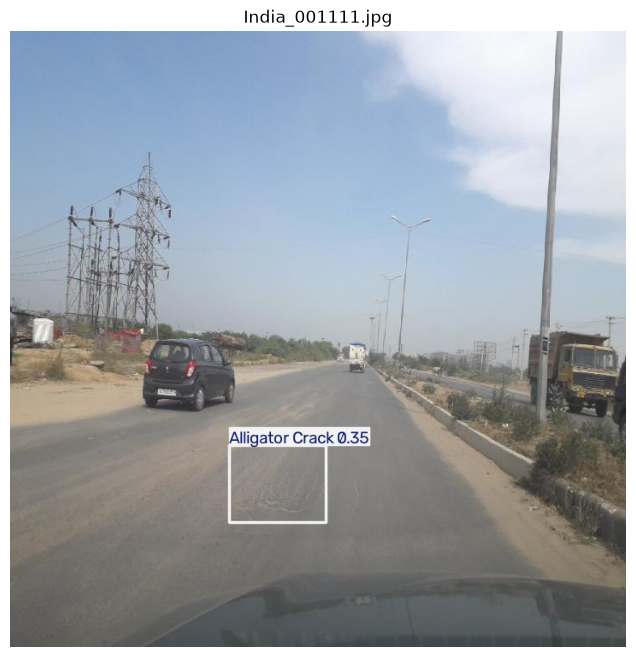

In [29]:
from pathlib import Path
import matplotlib.pyplot as plt
from ultralytics import YOLO

model = YOLO(str(BEST_WEIGHTS))
predictions = model.predict(
    source=[str(image_path) for image_path in sample_images],
    conf=0.25,
    save=False,
)

for result in predictions:
    annotated = result.plot()
    plt.figure(figsize=(8, 8))
    plt.imshow(annotated[:, :, ::-1])
    plt.title(Path(result.path).name)
    plt.axis("off")
    plt.show()

In [30]:
from pathlib import Path
import pandas as pd

results_file = RUN_DIR / "results.csv"
print("Results file exists:", results_file.exists())
print("Path:", results_file)

if results_file.exists():
    df = pd.read_csv(results_file)
    print("\nColumns:")
    print(df.columns.tolist())
    print("\nLast 10 epochs:")
    display(df.tail(10))

Results file exists: True
Path: d:\HONORS\RoadVision-AI\runs\road_damage_yolo26n\results.csv

Columns:
['epoch', 'time', 'train/box_loss', 'train/cls_loss', 'train/l1_loss', 'metrics/precision(B)', 'metrics/recall(B)', 'metrics/mAP50(B)', 'metrics/mAP50-95(B)', 'val/box_loss', 'val/cls_loss', 'val/l1_loss', 'lr/pg0', 'lr/pg1', 'lr/pg2', 'lr/pg3', 'lr/pg4', 'lr/pg5', 'lr/pg6', 'lr/pg7']

Last 10 epochs:


,epoch,time,train/box_loss,train/cls_loss,train/l1_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/l1_loss,lr/pg0,lr/pg1,lr/pg2,lr/pg3,lr/pg4,lr/pg5,lr/pg6,lr/pg7
40,41,11339.1,1.78237,1.95128,0.01870,0.53128,0.47107,0.48621,0.21690,1.81952,2.01451,0.01897,0.006240,0.002080,0.006240,0.002080,0.006240,0.002080,0.006240,0.002080
41,42,11583.7,1.76546,1.89854,0.01822,0.54071,0.46940,0.48896,0.21799,1.83350,1.98644,0.01927,0.005646,0.001882,0.005646,0.001882,0.005646,0.001882,0.005646,0.001882
42,43,11827.9,1.76197,1.84075,0.01806,0.54207,0.46932,0.49119,0.22006,1.82164,1.99627,0.01894,0.005052,0.001684,0.005052,0.001684,0.005052,0.001684,0.005052,0.001684
43,44,12066.8,1.74523,1.84076,0.01789,0.54118,0.47158,0.48760,0.21914,1.83582,1.98763,0.01909,0.004458,0.001486,0.004458,0.001486,0.004458,0.001486,0.004458,0.001486
44,45,12308.2,1.74099,1.81423,0.01782,0.54095,0.47122,0.48889,0.21724,1.83061,1.99508,0.01903,0.003864,0.001288,0.003864,0.001288,0.003864,0.001288,0.003864,0.001288
45,46,12555.0,1.74049,1.76892,0.01787,0.54496,0.46860,0.48894,0.21767,1.84062,1.98376,0.01908,0.003270,0.001090,0.003270,0.001090,0.003270,0.001090,0.003270,0.001090
46,47,12799.9,1.72538,1.73856,0.01732,0.55350,0.46643,0.48788,0.21733,1.85308,1.96748,0.01914,0.002676,0.000892,0.002676,0.000892,0.002676,0.000892,0.002676,0.000892
47,48,13043.2,1.71491,1.72130,0.01743,0.56887,0.45535,0.48619,0.21751,1.87137,1.94806,0.01944,0.002082,0.000694,0.002082,0.000694,0.002082,0.000694,0.002082,0.000694
48,49,13283.9,1.71070,1.71166,0.01727,0.56429,0.46082,0.48689,0.21709,1.87634,1.94464,0.01956,0.001488,0.000496,0.001488,0.000496,0.001488,0.000496,0.001488,0.000496
49,50,13525.7,1.69926,1.70904,0.01715,0.55821,0.45898,0.48630,0.21647,1.88335,1.93733,0.01966,0.000894,0.000298,0.000894,0.000298,0.000894,0.000298,0.000894,0.000298


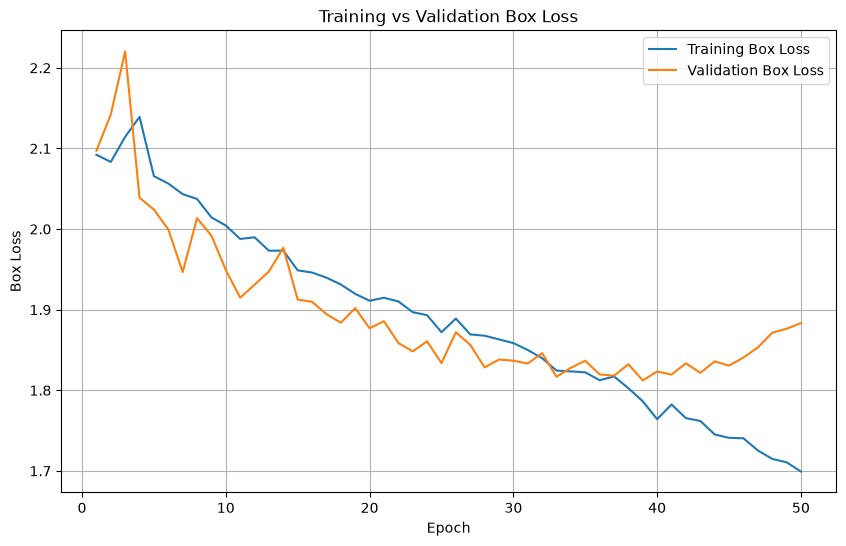

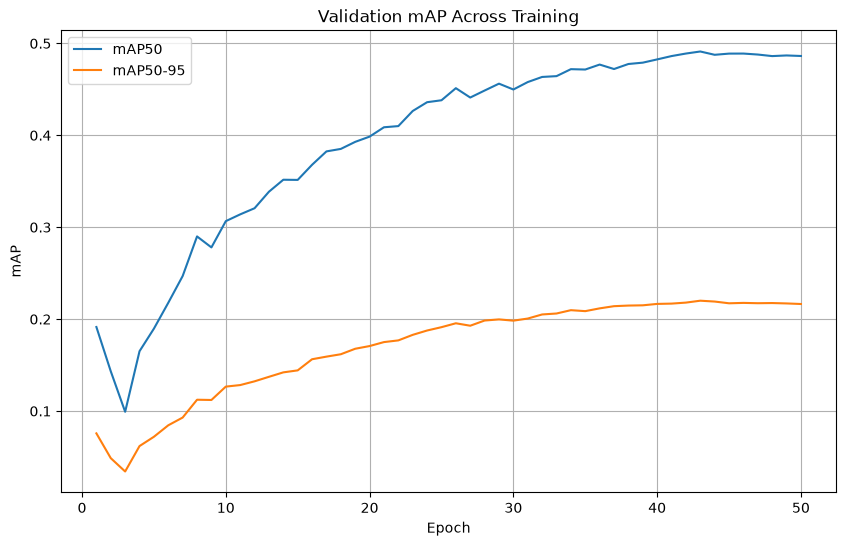

In [31]:
# Plot training loss and validation mAP
import matplotlib.pyplot as plt
import pandas as pd

df = pd.read_csv(RUN_DIR / "results.csv")

plt.figure(figsize=(10, 6))
plt.plot(df["epoch"], df["train/box_loss"], label="Training Box Loss")
plt.plot(df["epoch"], df["val/box_loss"], label="Validation Box Loss")
plt.xlabel("Epoch")
plt.ylabel("Box Loss")
plt.title("Training vs Validation Box Loss")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(10, 6))
plt.plot(df["epoch"], df["metrics/mAP50(B)"], label="mAP50")
plt.plot(df["epoch"], df["metrics/mAP50-95(B)"], label="mAP50-95")
plt.xlabel("Epoch")
plt.ylabel("mAP")
plt.title("Validation mAP Across Training")
plt.legend()
plt.grid(True)
plt.show()

In [32]:
from ultralytics import YOLO

model = YOLO(str(BEST_WEIGHTS))
results = model.val(
    data=str(YOLO_ROOT / "data.yaml"),
    split="test",
    conf=0.25,
    plots=True,
    save=True,
)

print("Test confusion matrix generated.")
print("Results saved to:", results.save_dir)

Ultralytics 8.4.177  Python-3.11.9 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5080, 16303MiB)
YOLO26n summary (fused): 121 layers, 2,390,464 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access  (ping: 0.0±0.0 ms, read: 974.9±274.2 MB/s, size: 72.4 KB)
val: Scanning D:\HONORS\RoadVision-AI\prepared_dataset\road_damage\labels\test.cache... 3157 images, 1361 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 3157/3157  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 198/198 8.8it/s 22.5s<0.1s
                   all       3157       3669      0.623      0.436      0.358      0.166
    Longitudinal Crack        654        946       0.58       0.34      0.254      0.107
      Transverse Crack        395        697      0.591      0.395      0.296      0.121
       Alligator Crack        979       1238      0.698      0.624      0.563        0.3
               Pothole        441        788      0.623      0.383      0.316      

Validation results: D:\HONORS\RoadVision-AI\notebook\runs\detect\val-2


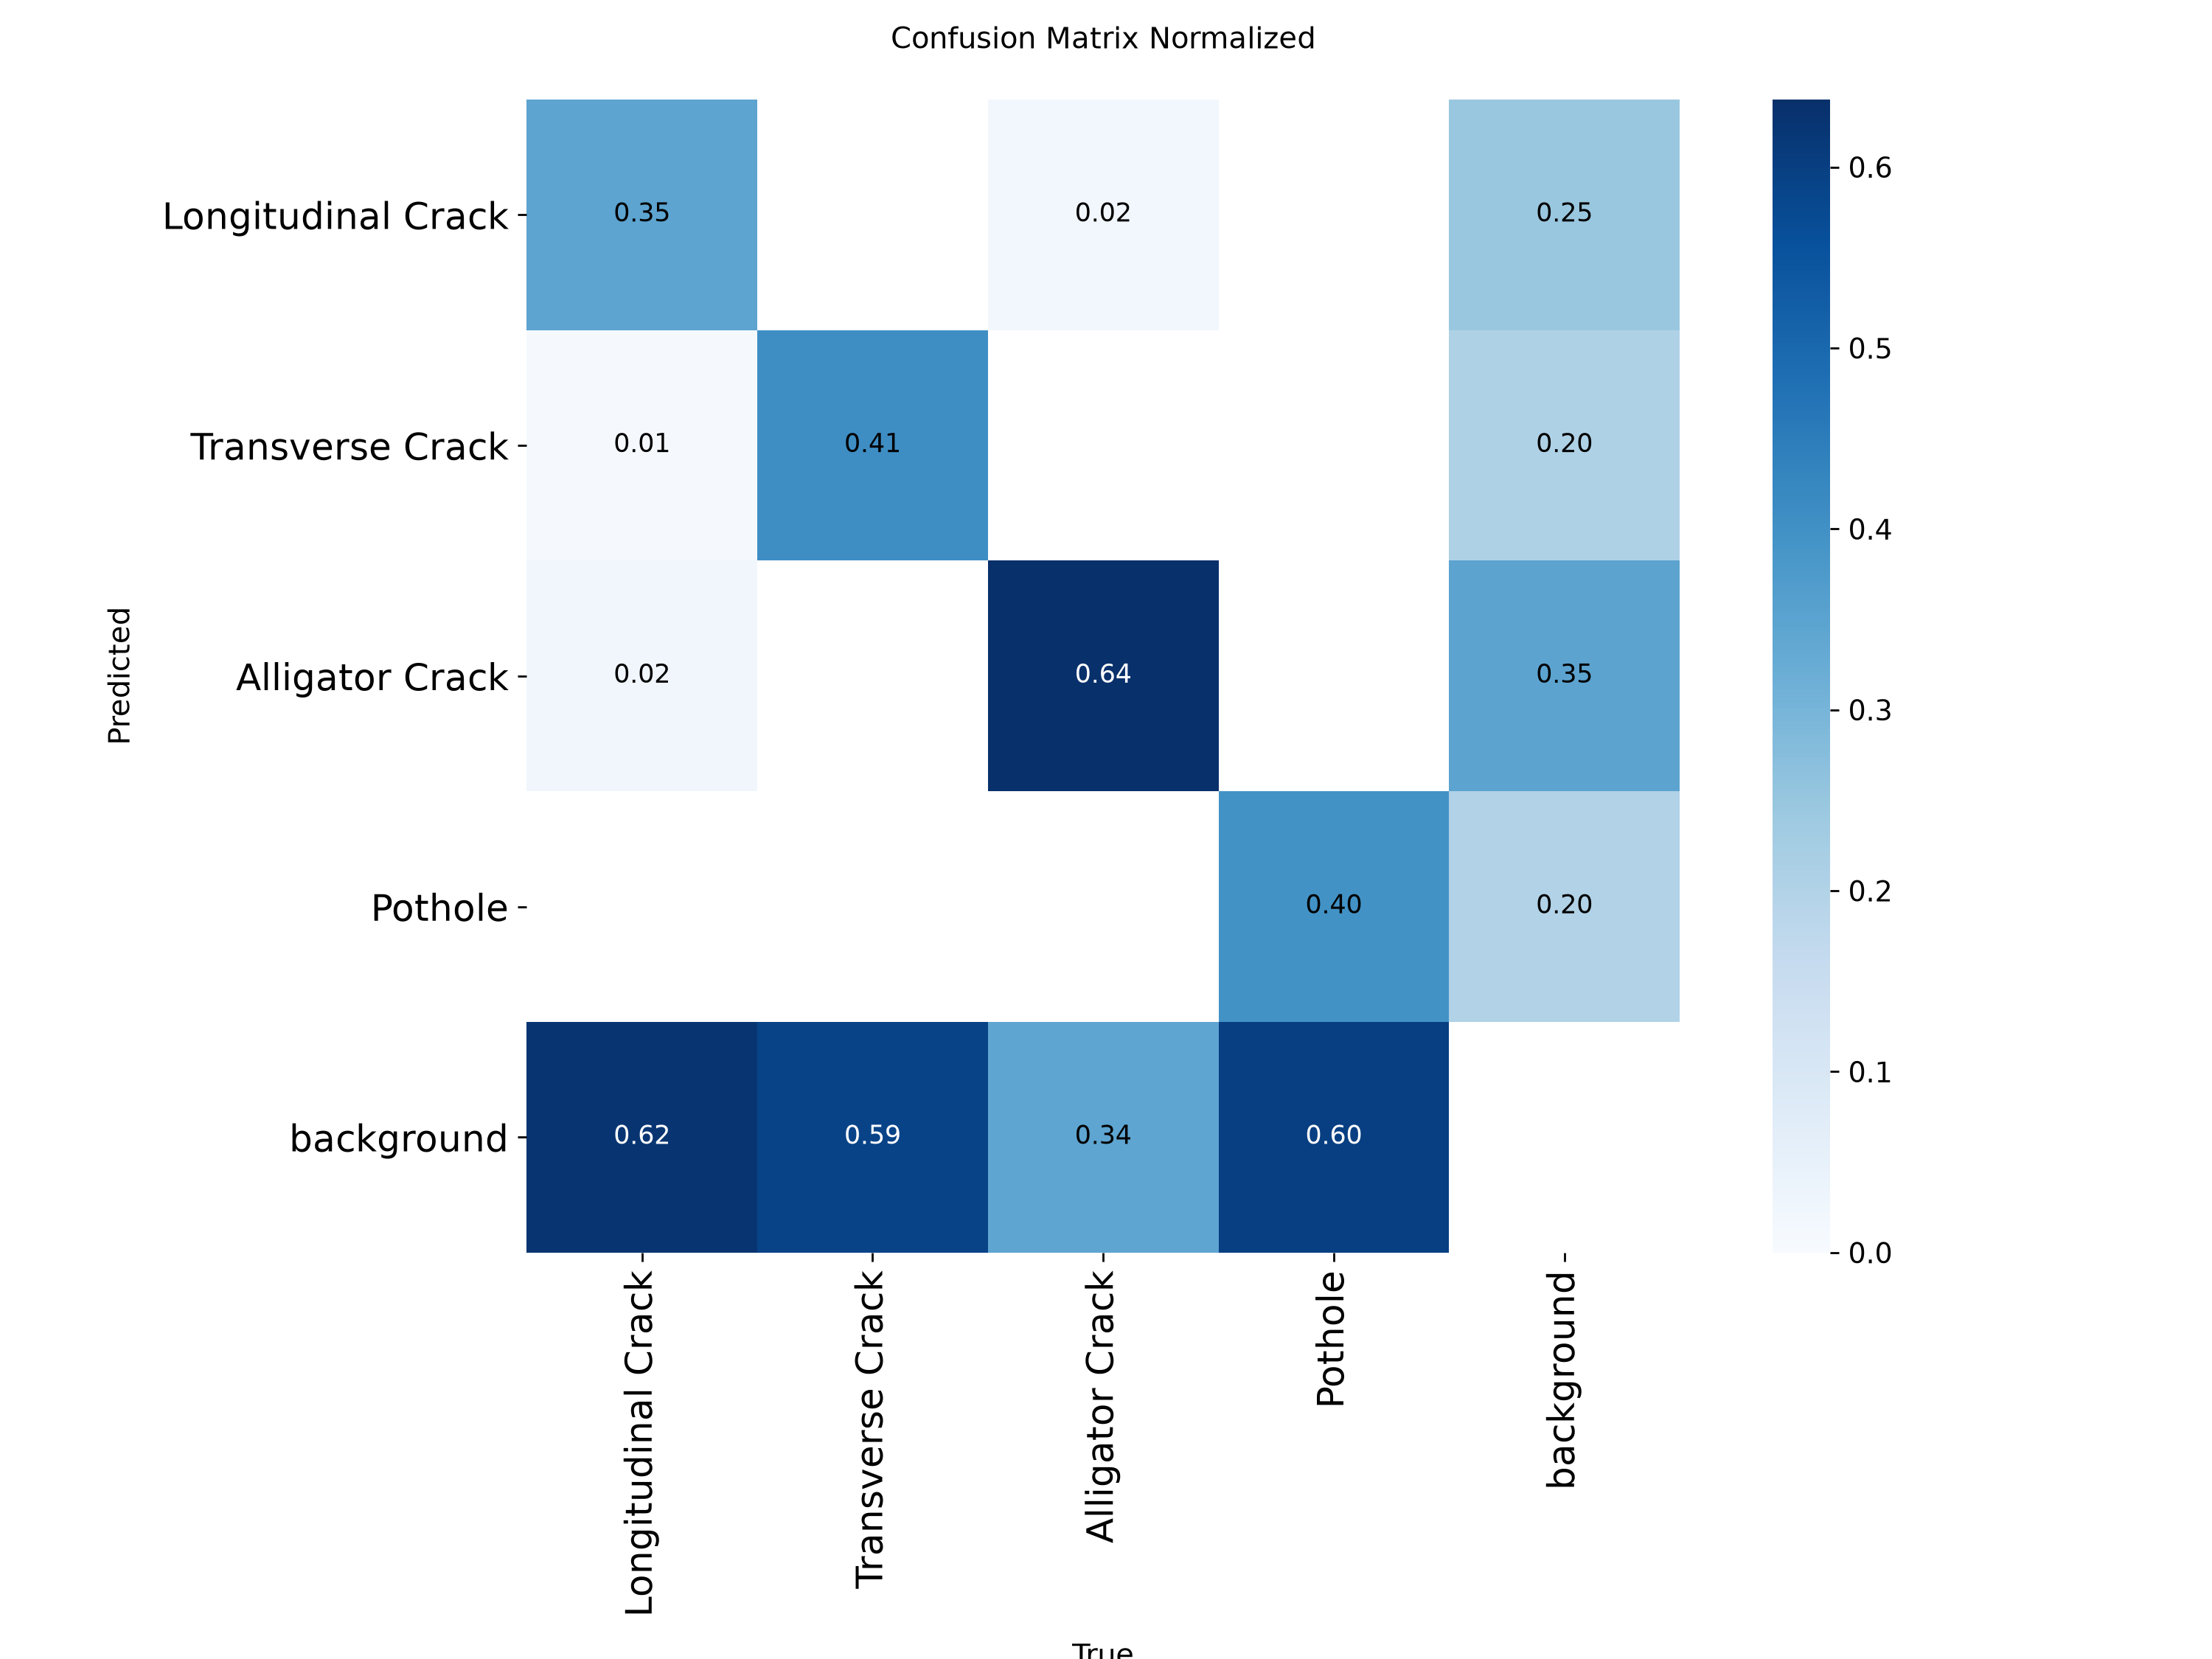

In [33]:
from pathlib import Path
from IPython.display import Image, display

result_dir = Path(results.save_dir)
print("Validation results:", result_dir)

cm = result_dir / "confusion_matrix_normalized.png"
if cm.exists():
    display(Image(filename=str(cm)))
else:
    print("Normalized confusion matrix not found.")